# EDA


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', 60)

### Loading the Dataset

In [5]:
df = pd.read_csv('../DataCoSupplyChainDataset.csv',encoding="latin-1")
print('Dataset Shape:', df.shape)
df.head(3)

Dataset Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

### Missing Values and Duplicates


In [9]:
null_counts = df.isnull().sum()
null_cols = null_counts[null_counts > 0]
print("Columns with missing values:")
for col, cnt in null_cols.items():
    print(f"  {col}: {cnt}")

print("\nDuplicate rows:", df.duplicated().sum())

Columns with missing values:
  Customer Lname: 8
  Customer Zipcode: 3
  Order Zipcode: 155679
  Product Description: 180519

Duplicate rows: 0


Target Counts:
                    Count  Proportion
Late_delivery_risk                   
1                   98977      0.5483
0                   81542      0.4517


<Axes: xlabel='Late_delivery_risk'>

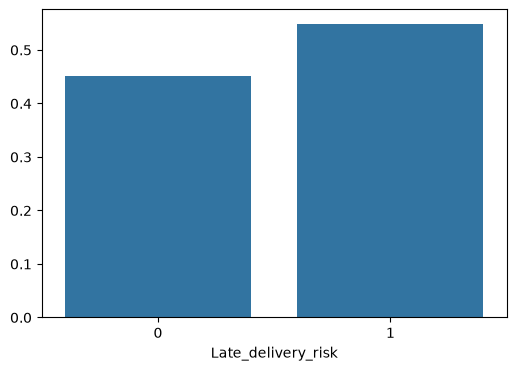

In [12]:
target_counts = df['Late_delivery_risk'].value_counts()
target_props = df['Late_delivery_risk'].value_counts(normalize=True)

print("Target Counts:")
print(pd.DataFrame({'Count': target_counts, 'Proportion': target_props.round(4)}))
plt.figure(figsize=(6, 4))
sns.barplot(x=target_props.index, y=target_props.values)

In [ ]:
print("Delivery Status breakdown by Late_delivery_risk:")
print(pd.crosstab(df['Delivery Status'], df['Late_delivery_risk'], margins=True))

print("\nDays for shipping (real) vs Late_delivery_risk:")
print(df.groupby('Late_delivery_risk')[['Days for shipping (real)', 'Days for shipment (scheduled)']].mean())

Delivery Status breakdown by Late_delivery_risk:
Late_delivery_risk      0      1     All
Delivery Status                         
Advance shipping    41592      0   41592
Late delivery           0  98977   98977
Shipping canceled    7754      0    7754
Shipping on time    32196      0   32196
All                 81542  98977  180519

Days for shipping (real) vs Late_delivery_risk:
                    Days for shipping (real)  Days for shipment (scheduled)
Late_delivery_risk                                                         
0                                   2.779561                       3.491146
1                                   4.089253                       2.471069


In [16]:
df.head(20)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class
5,TRANSFER,6,4,18.580000,294.980011,Shipping canceled,0,73,Sporting Goods,Tonawanda,EE. UU.,XXXXXXXXX,Kimberly,19488,Flowers,XXXXXXXXX,Consumer,NY,2122 Hazy Corner,14150.0,2,Fitness,43.013969,-78.879066,Pacific Asia,Toowoomba,Australia,19488,1/13/2018 11:03,75935,1360,32.779999,0.10,179250,327.75,0.06,1,327.75,294.980011,18.580000,Oceania,Queensland,CANCELED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/19/2018 11:03,Standard Class
6,DEBIT,2,1,95.180000,288.420013,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Constance,19487,Terrell,XXXXXXXXX,Home Office,PR,1879 Green Pine Bank,725.0,2,Fitness,18.242538,-66.037056,Pacific Asia,Guangzhou,China,19487,1/13/2018 10:42,75934,1360,39.330002,0.12,179249,327.75,

### Redundant and Duplicate Columns
Let's test pairs of columns that appear to hold identical information.

In [17]:
checks = {
    'Benefit per order vs Order Profit Per Order': (df['Benefit per order'] == df['Order Profit Per Order']).all(),
    'Sales per customer vs Order Item Total': (df['Sales per customer'] == df['Order Item Total']).all(),
    'Product Price vs Order Item Product Price': (df['Product Price'] == df['Order Item Product Price']).all(),
    'Customer Id vs Order Customer Id': (df['Customer Id'] == df['Order Customer Id']).all(),
    'Product Card Id vs Order Item Card Id': (df['Product Card Id'] == df['Order Item Cardprod Id']).all(),
    'Category Id vs Product Category Id': (df['Category Id'] == df['Product Category Id']).all()
}
for name, is_same in checks.items():
    print(f"{name}: {is_same}")

Benefit per order vs Order Profit Per Order: True
Sales per customer vs Order Item Total: True
Product Price vs Order Item Product Price: True
Customer Id vs Order Customer Id: True
Product Card Id vs Order Item Card Id: True
Category Id vs Product Category Id: True


here six have indentical copies so we will only one of them


In [ ]:
pd.crosstab(df['Shipping Mode'], df['Days for shipment (scheduled)'])

Days for shipment (scheduled),0,1,2,4
Shipping Mode,,,,
First Class,0,27814,0,0
Same Day,9737,0,0,0
Second Class,0,0,35216,0
Standard Class,0,0,0,107752


`Days for shipment (scheduled)` is completely collinear with `Shipping Mode`:

                total_orders  late_orders  late_rate  scheduled_days
Shipping Mode                                                       
First Class            27814        26513   0.953225               1
Same Day                9737         4454   0.457430               0
Second Class           35216        26987   0.766328               2
Standard Class        107752        41023   0.380717               4


<Axes: xlabel='Shipping Mode', ylabel='late_rate'>

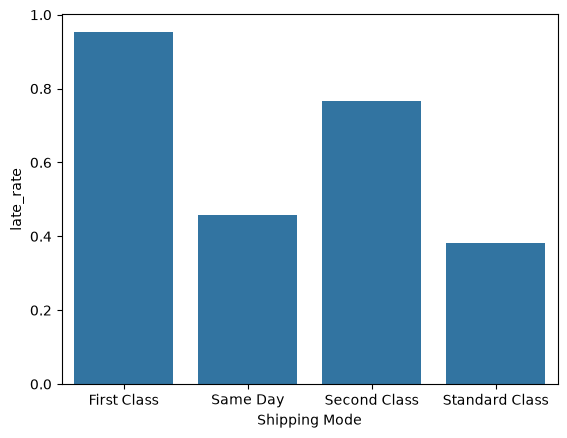

In [20]:
mode_stats = df.groupby('Shipping Mode').agg(
    total_orders=('Late_delivery_risk', 'count'),
    late_orders=('Late_delivery_risk', 'sum'),
    late_rate=('Late_delivery_risk', 'mean'),
    scheduled_days=('Days for shipment (scheduled)', 'first')
)

print(mode_stats)

sns.barplot(data=mode_stats, x='Shipping Mode', y='late_rate')

Percentage of orders taking N real shipping days:
Days for shipping (real)     0     1    2    3    4    5    6
Shipping Mode                                                
First Class               0.00  0.00  1.0  0.0  0.0  0.0  0.0
Same Day                  0.52  0.48  0.0  0.0  0.0  0.0  0.0
Second Class              0.00  0.00  0.2  0.2  0.2  0.2  0.2
Standard Class            0.00  0.00  0.2  0.2  0.2  0.2  0.2


<Axes: xlabel='Days for shipping (real)', ylabel='count'>

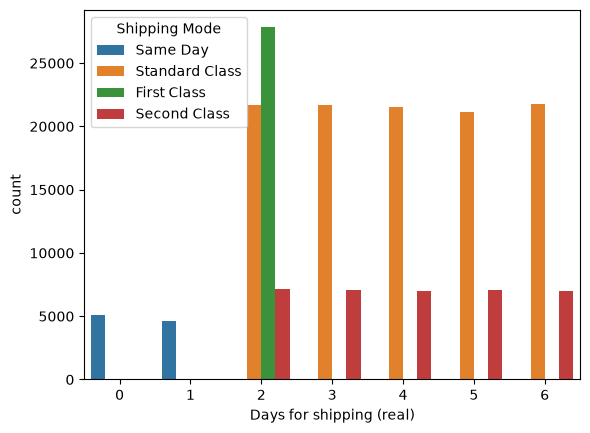

In [25]:
real_vs_mode = pd.crosstab(df['Shipping Mode'], df['Days for shipping (real)'], normalize='index')
print("Percentage of orders taking N real shipping days:")
print(real_vs_mode.round(2))
sns.countplot(data=df, x='Days for shipping (real)', hue='Shipping Mode')

### Late Rates Across Geographic and Customer Dimensions

Top 10 Order Regions by Volume and their Late Rate:
                 count      mean
Order Region                    
Central America  28341  0.547546
Western Europe   27109  0.558486
South America    14935  0.543087
Oceania          10148  0.540205
Northern Europe   9792  0.540441
Southeast Asia    9539  0.555299
Southern Europe   9431  0.543845
Caribbean         8318  0.530777
West of USA       7993  0.539597
South Asia        7731  0.562670


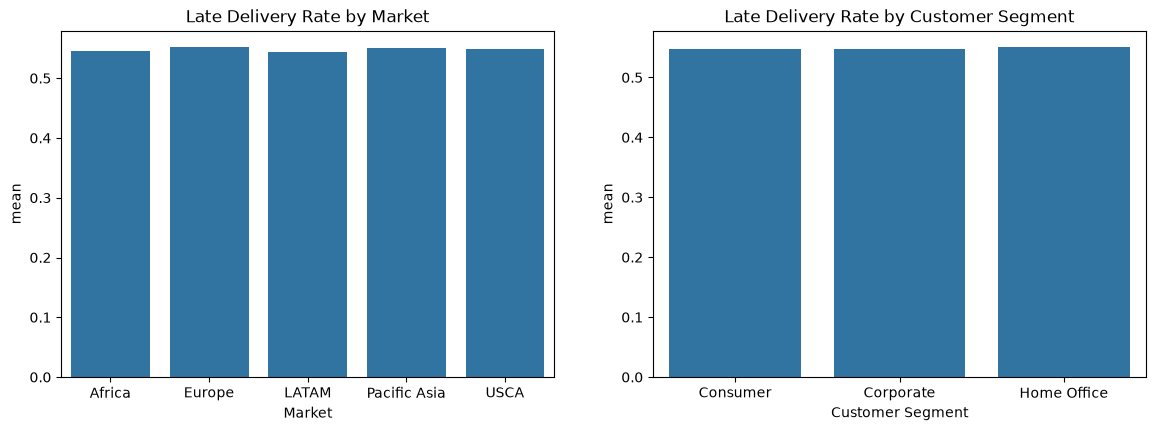

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

market_stats = df.groupby('Market')['Late_delivery_risk'].agg(['count', 'mean']).reset_index()
sns.barplot(ax=axes[0], data=market_stats, x='Market', y='mean')
axes[0].set_title('Late Delivery Rate by Market')

segment_stats = df.groupby('Customer Segment')['Late_delivery_risk'].agg(['count', 'mean']).reset_index()

sns.barplot(ax=axes[1], data=segment_stats, x='Customer Segment', y='mean')
axes[1].set_title('Late Delivery Rate by Customer Segment')



print("Top 10 Order Regions by Volume and their Late Rate:")
print(df.groupby('Order Region')['Late_delivery_risk'].agg(['count', 'mean']).sort_values('count', ascending=False).head(10))

Text(0, 0.5, 'Late Rate')

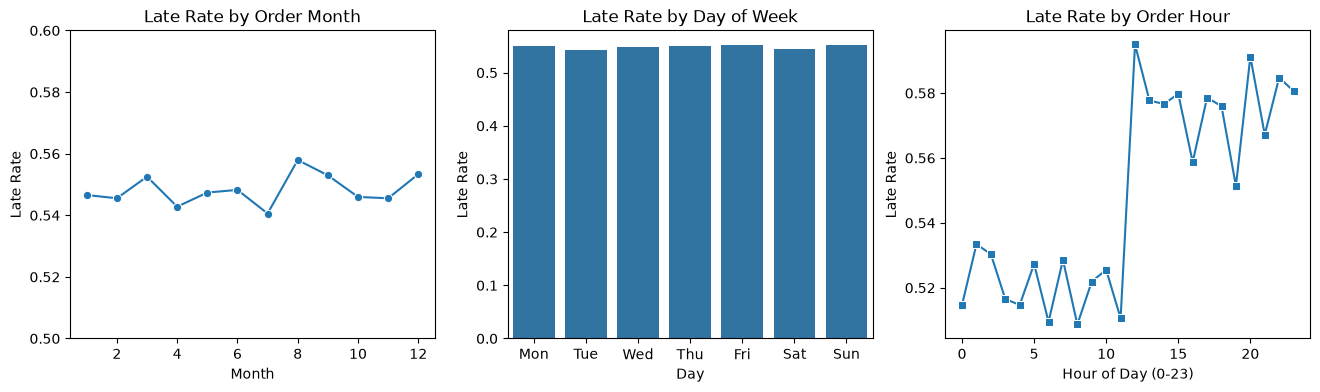

In [36]:
df['order_dt'] = pd.to_datetime(df['order date (DateOrders)'])
df['order_month'] = df['order_dt'].dt.month
df['order_dow'] = df['order_dt'].dt.day_name()
df['order_hour'] = df['order_dt'].dt.hour

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

month_stats = df.groupby('order_month')['Late_delivery_risk'].mean()

sns.lineplot(ax=axes[0], x=month_stats.index, y=month_stats.values, marker='o')
axes[0].set_title('Late Rate by Order Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Late Rate')
axes[0].set_ylim(0.50, 0.60)

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_stats = df.groupby('order_dow')['Late_delivery_risk'].mean().reindex(dow_order)
sns.barplot(ax=axes[1], x=dow_stats.index, y=dow_stats.values)
axes[1].set_title('Late Rate by Day of Week')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Late Rate')
axes[1].set_xticks(range(len(dow_order)))
axes[1].set_xticklabels([d[:3] for d in dow_order])


hour_stats = df.groupby('order_hour')['Late_delivery_risk'].mean()
sns.lineplot(ax=axes[2], x=hour_stats.index, y=hour_stats.values, marker='s')

axes[2].set_title('Late Rate by Order Hour')
axes[2].set_xlabel('Hour of Day (0-23)')
axes[2].set_ylabel('Late Rate')


Summary statistics of key numeric order features:
           Sales  Order Item Quantity  Order Item Discount  \
count  180519.00            180519.00            180519.00   
mean      203.77                 2.13                20.66   
std       132.27                 1.45                21.80   
min         9.99                 1.00                 0.00   
25%       119.98                 1.00                 5.40   
50%       199.92                 1.00                14.00   
75%       299.95                 3.00                29.99   
max      1999.99                 5.00               500.00   

       Order Item Discount Rate  Order Item Product Price  Order Item Total  
count                 180519.00                 180519.00         180519.00  
mean                       0.10                    141.23            183.11  
std                        0.07                    139.73            120.04  
min                        0.00                      9.99              7.49  
2

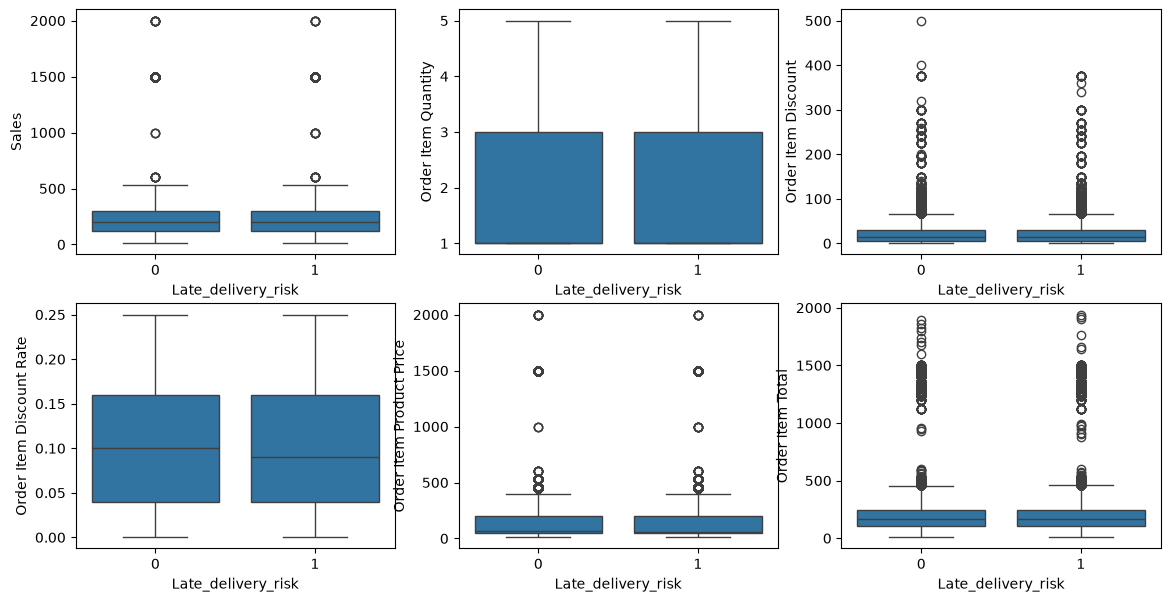

In [39]:
numeric_order_features = [
    'Sales', 'Order Item Quantity', 'Order Item Discount', 
    'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Total'
]

print("Summary statistics of key numeric order features:")
print(df[numeric_order_features].describe().round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()
for idx, col in enumerate(numeric_order_features):
    sns.boxplot(ax=axes[idx], x=df['Late_delivery_risk'], y=df[col])
   
    

plt.show()

The distributions of order quantity, price, sales, and discounts are virtually identical between late and on-time orders.
Let's calculate correlation with the target for all numeric columns.

Correlation with Late_delivery_risk:
Late_delivery_risk               1.0000
Days for shipping (real)         0.4014
Customer Zipcode                 0.0031
Category Id                      0.0018
Product Category Id              0.0018
Order Item Cardprod Id           0.0015
Product Card Id                  0.0015
Order Customer Id                0.0015
Customer Id                      0.0015
Department Id                    0.0011
Latitude                         0.0007
Order Item Discount Rate         0.0004
Order Item Quantity             -0.0001
Order Item Discount             -0.0007
Order Id                        -0.0013
Order Item Id                   -0.0014
Longitude                       -0.0019
Product Price                   -0.0022
Order Item Product Price        -0.0022
Order Item Profit Ratio         -0.0023
Sales                           -0.0036
Benefit per order               -0.0037
Order Profit Per Order          -0.0037
Order Item Total                -0.0038
Sal

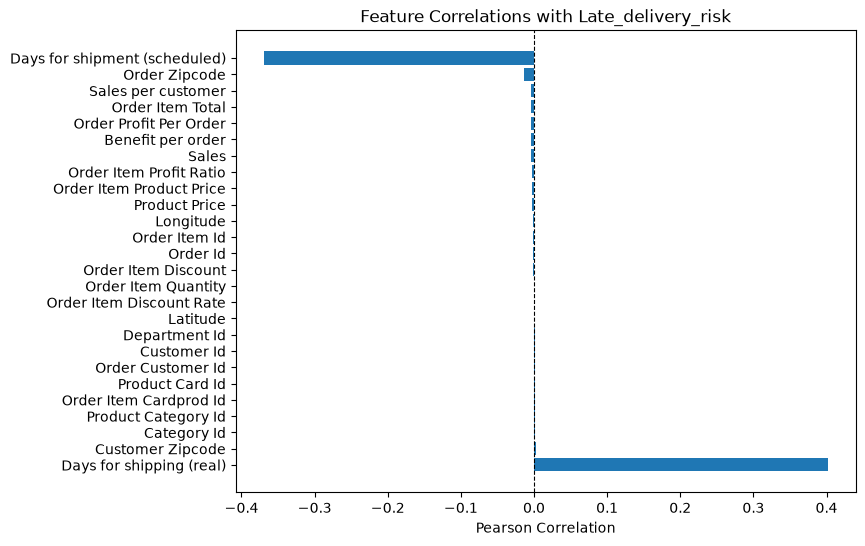

In [40]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
correlations = df[num_cols].corrwith(df['Late_delivery_risk']).sort_values(ascending=False)

print("Correlation with Late_delivery_risk:")
print(correlations.round(4))

plt.figure(figsize=(8, 6))
top_corr = correlations.dropna().drop(['Late_delivery_risk'])
plt.barh(top_corr.index, top_corr.values)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Feature Correlations with Late_delivery_risk')
plt.xlabel('Pearson Correlation')
plt.show()

Only `Days for shipping (real)` (+0.4014) and `Days for shipment (scheduled)` (-0.3694) have significant linear correlation with `Late_delivery_risk`.
All other numerical features (Sales, Discount, Quantity, Product Price, Profit) have near-zero correlations (between -0.014 and +0.003).

### Summary of Columns to Drop and Clean
To prevent data leakage, remove redundant data, and protect privacy, we categorize columns to drop:
1. Target Leakage: `Days for shipping (real)`, `Delivery Status`, `shipping date (DateOrders)`, `Order Status`.
2. Duplicate Columns: `Benefit per order` (duplicate of `Order Profit Per Order`), `Sales per customer` (duplicate of `Order Item Total`), `Product Price` (duplicate of `Order Item Product Price`), `Customer Id` (duplicate of `Order Customer Id`), `Product Card Id` (duplicate of `Order Item Cardprod Id`), `Category Id` (duplicate of `Product Category Id`).
3. Identifiers and PII: `Order Id`, `Order Item Id`, `Order Customer Id`, `Order Item Cardprod Id`, `Product Category Id`, `Department Id`, `Customer Email`, `Customer Password`, `Customer Fname`, `Customer Lname`, `Customer Street`, `Customer Zipcode`.
4. Unusable / High Missing Columns: `Product Description` (100% null), `Order Zipcode` (86.2% null), `Product Status` (single constant value 0), `Product Image` (image URL string).

In [ ]:
leakage_cols = ['Days for shipping (real)', 'Delivery Status', 'shipping date (DateOrders)', 'Order Status']
duplicate_cols = ['Benefit per order', 'Sales per customer', 'Product Price', 'Customer Id', 'Product Card Id', 'Category Id']
pii_id_cols = ['Order Id', 'Order Item Id', 'Order Customer Id', 'Order Item Cardprod Id', 'Product Category Id', 
               'Department Id', 'Customer Email', 'Customer Password', 'Customer Fname', 'Customer Lname', 'Customer Street',
               'Customer Zipcode', 'Product Description', 'Product Status', 'Product Image', 'Order Zipcode']

all_drop_cols = sorted(list(set(leakage_cols + duplicate_cols + pii_id_cols)))
print(f"Total columns flagged for dropping: {len(all_drop_cols)}")
for col in all_drop_cols:
    print(f" - {col}")

Total columns flagged for dropping: 26
 - Benefit per order
 - Category Id
 - Customer Email
 - Customer Fname
 - Customer Id
 - Customer Lname
 - Customer Password
 - Customer Street
 - Customer Zipcode
 - Days for shipping (real)
 - Delivery Status
 - Department Id
 - Order Customer Id
 - Order Id
 - Order Item Cardprod Id
 - Order Item Id
 - Order Status
 - Order Zipcode
 - Product Card Id
 - Product Category Id
 - Product Description
 - Product Image
 - Product Price
 - Product Status
 - Sales per customer
 - shipping date (DateOrders)
